In [1]:
from google.colab import files
uploaded = files.upload()

Saving 3) Sentiment dataset.csv to 3) Sentiment dataset.csv


In [6]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("3) Sentiment dataset.csv")

df.columns = df.columns.str.strip().str.lower()

df = df.dropna(subset=["text", "sentiment"])

print("Dataset shape:", df.shape)
print("\nSentiment categories:")
print(df["sentiment"].value_counts())

df.head()

Dataset shape: (732, 15)

Sentiment categories:
sentiment
Positive               44
Joy                    42
Excitement             32
Happy                  14
Neutral                14
                       ..
Vibrancy                1
Culinary Adventure      1
Mesmerizing             1
Thrilling Journey       1
Winter Magic            1
Name: count, Length: 279, dtype: int64


,unnamed: 0.1,unnamed: 0,text,sentiment,timestamp,user,platform,hashtags,retweets,likes,country,year,month,day,hour
0,0,0,Enjoying a beautiful day at the park! ...,Positive,2023-01-15 12:30:00,User123,Twitter,#Nature #Park,15.0,30.0,USA,2023,1,15,12
1,1,1,Traffic was terrible this morning. ...,Negative,2023-01-15 08:45:00,CommuterX,Twitter,#Traffic #Morning,5.0,10.0,Canada,2023,1,15,8
2,2,2,Just finished an amazing workout! 💪 ...,Positive,2023-01-15 15:45:00,FitnessFan,Instagram,#Fitness #Workout,20.0,40.0,USA,2023,1,15,15
3,3,3,Excited about the upcoming weekend getaway! ...,Positive,2023-01-15 18:20:00,AdventureX,Facebook,#Travel #Adventure,8.0,15.0,UK,2023,1,15,18
4,4,4,Trying out a new recipe for dinner tonight. ...,Neutral,2023-01-15 19:55:00,ChefCook,Instagram,#Cooking #Food,12.0,25.0,Australia,2023,1,15,19


In [7]:
df["text"] = df["text"].astype(str)
df["clean_text"] = (
    df["text"]
    .str.lower()
    .str.replace(r"http\S+|www\S+", "", regex=True)
    .str.replace(r"[^a-z\s]", "", regex=True)
    .str.replace(r"\s+", " ", regex=True)
    .str.strip()
)

df = df[df["clean_text"] != ""]

print("Text cleaning completed.")
df[["text", "clean_text", "sentiment"]].head()

Text cleaning completed.


,text,clean_text,sentiment
0,Enjoying a beautiful day at the park! ...,enjoying a beautiful day at the park,Positive
1,Traffic was terrible this morning. ...,traffic was terrible this morning,Negative
2,Just finished an amazing workout! 💪 ...,just finished an amazing workout,Positive
3,Excited about the upcoming weekend getaway! ...,excited about the upcoming weekend getaway,Positive
4,Trying out a new recipe for dinner tonight. ...,trying out a new recipe for dinner tonight,Neutral


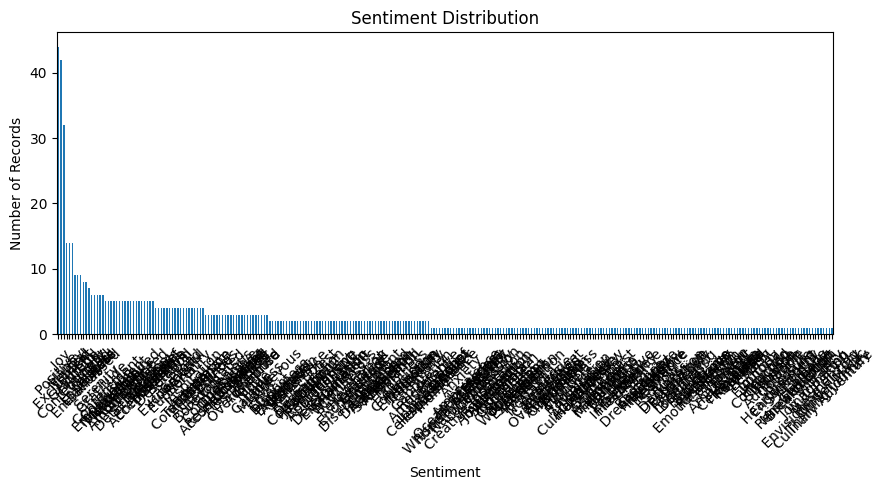

In [8]:
df["sentiment"].value_counts().plot(
    kind="bar", figsize=(9, 5)
)

plt.title("Sentiment Distribution")
plt.xlabel("Sentiment")
plt.ylabel("Number of Records")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

Top 10 most common words:


,Word,Frequency
0,through,52
1,new,43
2,each,39
3,like,27
4,day,26
5,feeling,26
6,after,25
7,into,25
8,dreams,25
9,laughter,24


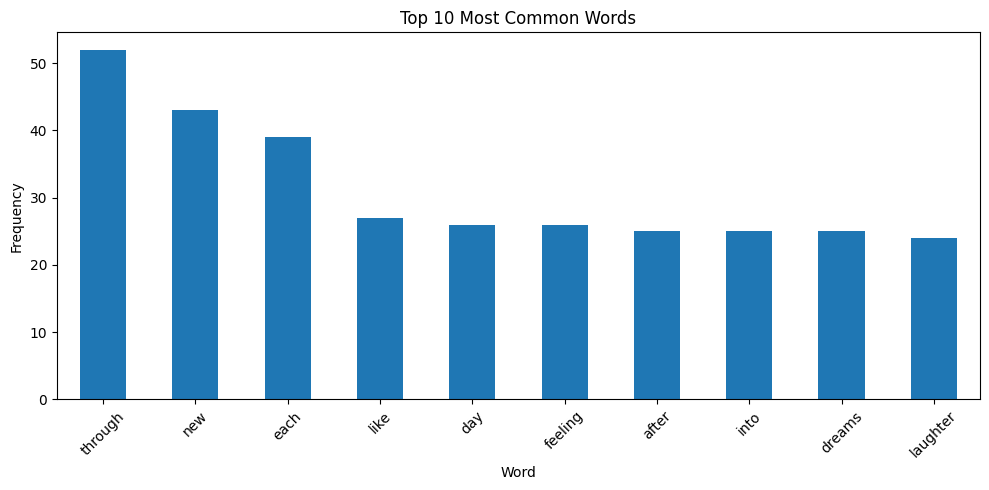

In [9]:
from collections import Counter
import re

all_words = " ".join(df["clean_text"]).split()

stop_words = {
    "the", "is", "a", "an", "and", "to", "of", "in",
    "it", "for", "on", "this", "that", "with", "was",
    "are", "i", "you", "my", "we", "they", "at", "be"
}

words = [
    word for word in all_words
    if word not in stop_words and len(word) > 2
]

common_words = Counter(words).most_common(10)

word_df = pd.DataFrame(common_words, columns=["Word", "Frequency"])

print("Top 10 most common words:")
display(word_df)

word_df.plot(
    x="Word", y="Frequency", kind="bar",
    legend=False, figsize=(10, 5)
)

plt.title("Top 10 Most Common Words")
plt.xlabel("Word")
plt.ylabel("Frequency")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

sentiment,Acceptance,Acceptance,Accomplishment,Admiration,Admiration,Admiration,Adoration,Adrenaline,Adventure,Affection,...,Vibrancy,Whimsy,Whispers of the Past,Winter Magic,Wonder,Wonder,Wonder,Wonderment,Yearning,Zest
platform,,,,,,,,,,,,,,,,,,,,,
Facebook,2,2,3,0,0,0,0,1,0,0,...,0,0,0,1,0,0,0,0,1,0
Instagram,0,2,0,1,0,1,0,0,0,2,...,1,2,0,0,1,1,1,0,1,1
Twitter,0,0,0,0,0,0,0,0,2,0,...,0,0,1,0,0,0,0,0,0,1
Twitter,1,1,0,0,2,0,2,0,1,0,...,0,0,0,0,0,0,0,1,0,0


/tmp/ipykernel_6480/555460889.py:15: UserWarning: Tight layout not applied. The bottom and top margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()


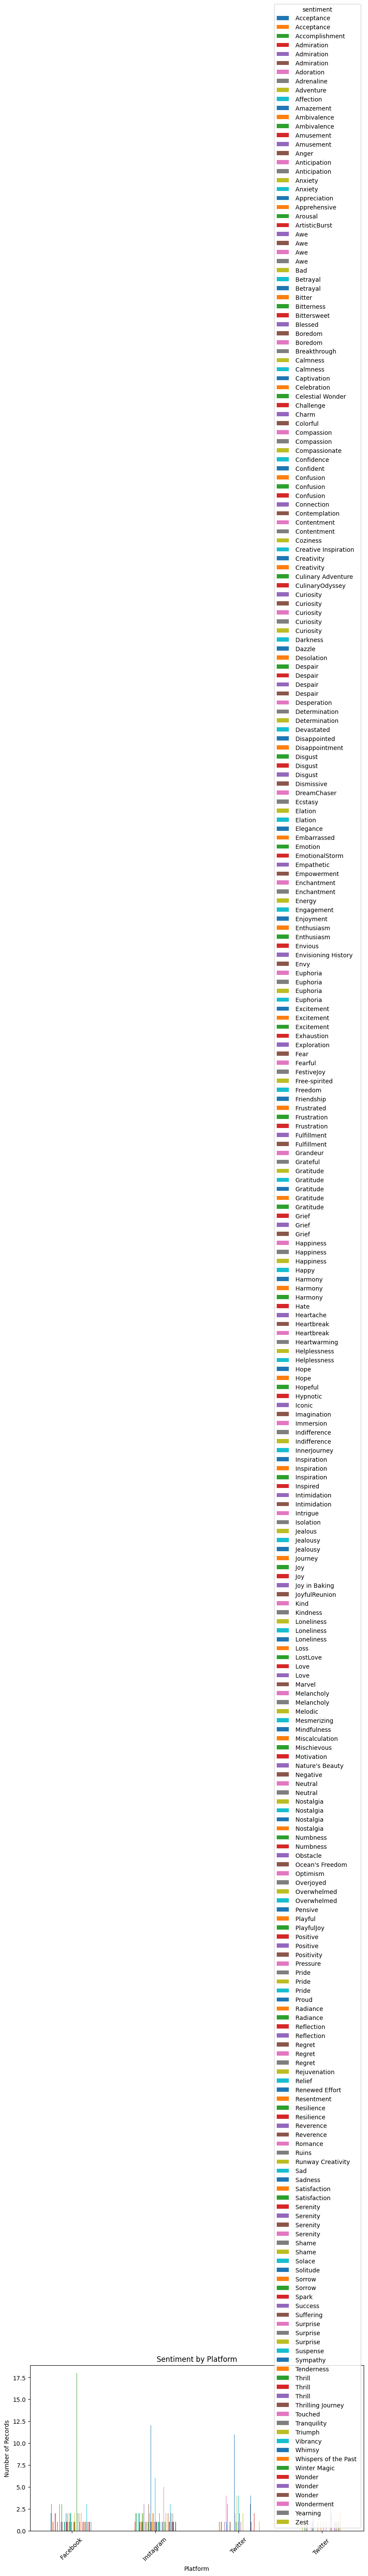

In [10]:
platform_sentiment = pd.crosstab(
    df["platform"], df["sentiment"]
)

display(platform_sentiment)

platform_sentiment.plot(
    kind="bar", figsize=(10, 5)
)

plt.title("Sentiment by Platform")
plt.xlabel("Platform")
plt.ylabel("Number of Records")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()